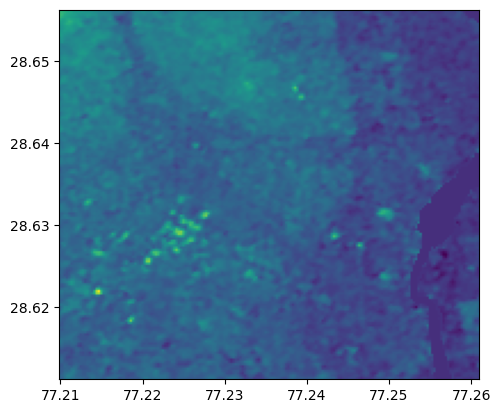

In [1]:
import matplotlib.pyplot as plt
import rasterio
from rasterio.plot import show

# Open and plot with geographic coordinates on the axes
with rasterio.open('output_SRTMGL1.tif') as src:
    show(src)

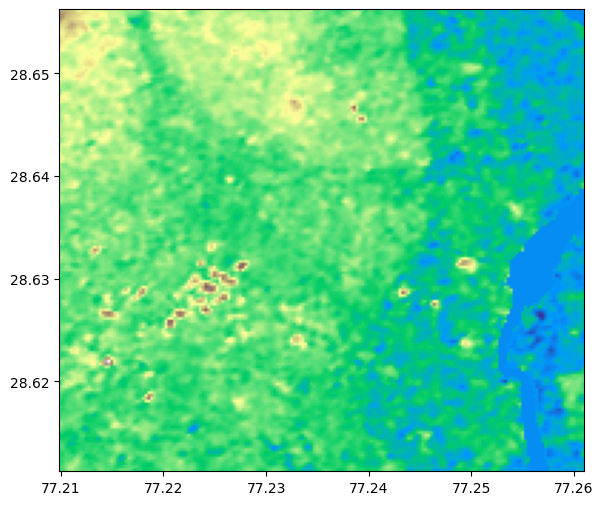

In [2]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt


with rasterio.open('output_SRTMGL1.tif') as src:
    data = src.read(1).astype(float)
    bounds = src.bounds

plt.figure(figsize=(8,6))
im = plt.imshow(data, cmap='terrain', extent=[bounds.left, bounds.right, bounds.bottom, bounds.top])

Saved flow_accumulation.png


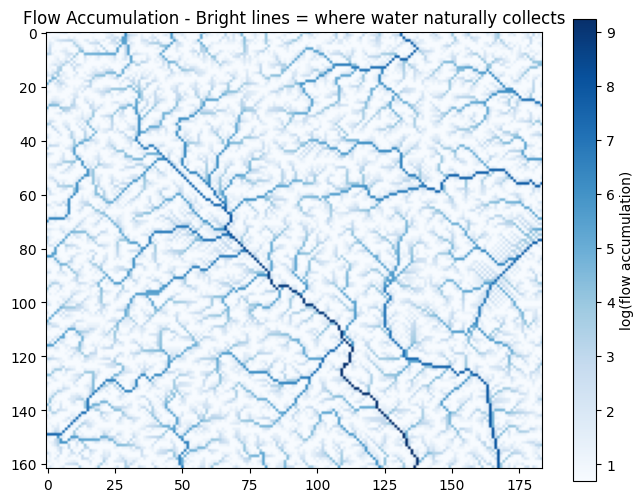

In [3]:
"""
Just the flow accumulation visualization (the blue drainage lines).
Put output_SRTMGL1.tif in the same folder as this script, then run it.
"""

import numpy as np
np.in1d = np.isin  # compatibility fix for pysheds + newer numpy

from pysheds.grid import Grid
import matplotlib.pyplot as plt

DEM_PATH = "output_SRTMGL1.tif"  # change if your file is named differently

# Load the DEM and clean up fake pits/depressions/flats so flow calculation works correctly
grid = Grid.from_raster(DEM_PATH)
dem = grid.read_raster(DEM_PATH)
pit_filled = grid.fill_pits(dem)
flooded = grid.fill_depressions(pit_filled)
inflated = grid.resolve_flats(flooded)

# flowdir: which direction water flows from each pixel
# accumulation: how much upstream water passes through each pixel (high = channel/drain path)
fdir = grid.flowdir(inflated)
acc = np.array(grid.accumulation(fdir))

# log1p scaling: accumulation values range from ~1 to over 10,000, so without a log
# scale only the single biggest channel would be visible and everything else would
# look pure black. log1p makes both small and large channels visible together.
plt.figure(figsize=(8, 6))
im = plt.imshow(np.log1p(acc), cmap='Blues')
plt.colorbar(im, label='log(flow accumulation)')
plt.title('Flow Accumulation - Bright lines = where water naturally collects')
plt.savefig('flow_accumulation.png', dpi=150, bbox_inches='tight')
print("Saved flow_accumulation.png")
plt.show()

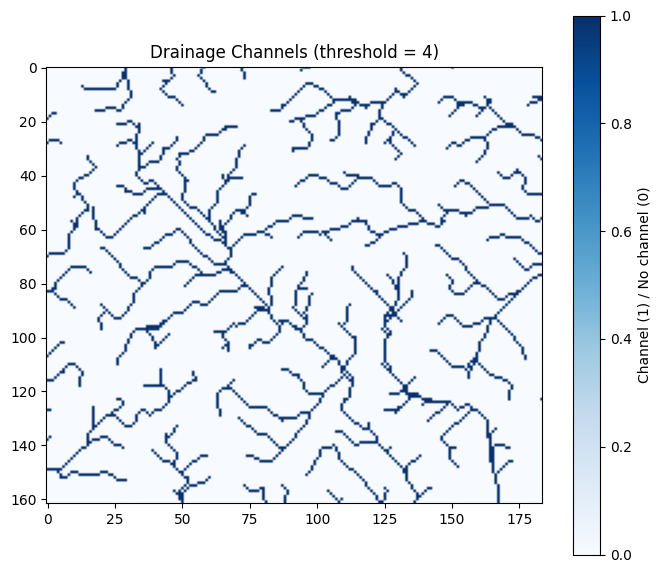

Saved drainage_channels.png
Percent of area classified as channel: 7.66%


In [5]:
import numpy as np
import matplotlib.pyplot as plt

# your flow accumulation array should already exist as something like `flow_acc`
# if it's already log-transformed for plotting, work on the raw values instead

log_flow = np.log1p(acc)   # log1p = log(1+x), avoids errors on zero values

# --- pick your threshold here ---
threshold = 4   # try 4, 5, 6 and see what looks clean

# create a mask: True where flow is above threshold, False elsewhere
channel_mask = log_flow > threshold

# plot it
plt.figure(figsize=(8, 7))
plt.imshow(channel_mask, cmap='Blues')
plt.title(f"Drainage Channels (threshold = {threshold})")
plt.colorbar(label="Channel (1) / No channel (0)")
plt.savefig("drainage_channels.png", dpi=150)
plt.show()

print("Saved drainage_channels.png")
print(f"Percent of area classified as channel: {channel_mask.mean()*100:.2f}%")

Saved slope.png
Min slope: 0.00°, Max slope: 39.49°, Mean: 3.13°


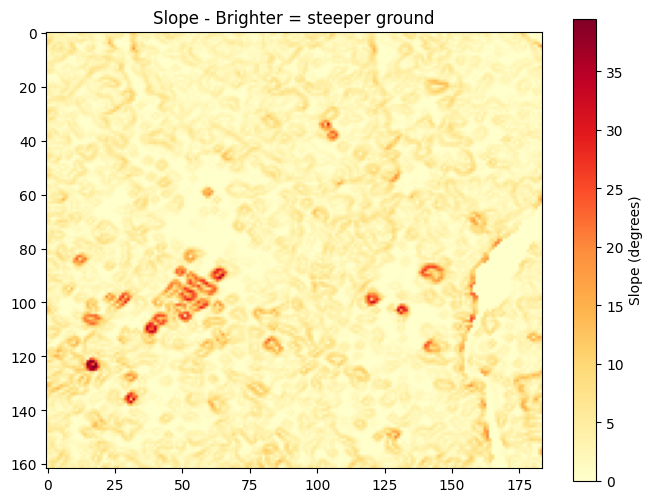

In [7]:
# --- SLOPE: how steep the ground is at each point ---
# Convert pixel size from degrees to meters (DEM is in lat/lon degrees, not meters)
latitude = 28.63  # approximate center latitude of your pilot area
meters_per_degree_lat = 111320
meters_per_degree_lon = 111320 * np.cos(np.radians(latitude))

cellsize_deg = grid.affine[0]  # pixel width in degrees
cellsize_x_m = cellsize_deg * meters_per_degree_lon
cellsize_y_m = cellsize_deg * meters_per_degree_lat

dem_array = np.array(inflated)
dzdy, dzdx = np.gradient(dem_array, cellsize_y_m, cellsize_x_m)
slope = np.sqrt(dzdx**2 + dzdy**2)
slope_degrees = np.degrees(np.arctan(slope))

plt.figure(figsize=(8, 6))
im = plt.imshow(slope_degrees, cmap='YlOrRd')
plt.colorbar(im, label='Slope (degrees)')
plt.title('Slope - Brighter = steeper ground')
plt.savefig('slope.png', dpi=150, bbox_inches='tight')
print("Saved slope.png")
print(f"Min slope: {slope_degrees.min():.2f}°, Max slope: {slope_degrees.max():.2f}°, Mean: {slope_degrees.mean():.2f}°")

plt.show()

C:\Users\Work\AppData\Local\Temp\ipykernel_7408\2630392062.py:35: UserWarning: Geometry is in a geographic CRS. Results from 'buffer' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  roads["geometry"] = roads.geometry.buffer(buffer_degrees)


Saved imperviousness.tif
Percent of area covered by roads/buildings: 27.89%
Saved imperviousness.png


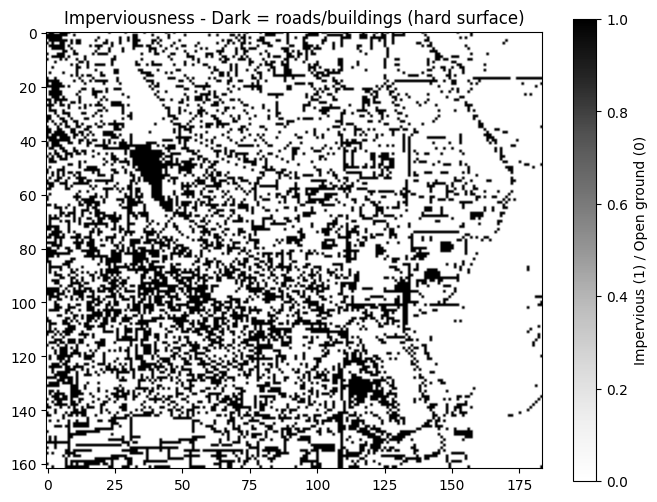

In [8]:
"""
Build an imperviousness layer from buildings.geojson and roads.geojson,
aligned to the same grid as your DEM (output_SRTMGL1.tif).
"""
import geopandas as gpd
import rasterio
from rasterio import features
import numpy as np
import matplotlib.pyplot as plt

DEM_PATH = "output_SRTMGL1.tif"
BUILDINGS_PATH = "export_buildings.geojson"
ROADS_PATH = "export_roads.geojson"
ROAD_BUFFER_METERS = 5  # assume an average road is ~5m wide since OSM roads are just lines, not shapes

# --- Load the DEM just to copy its grid shape and coordinate system ---
with rasterio.open(DEM_PATH) as src:
    dem_shape = src.shape          # (height, width) — should be (162, 184)
    dem_transform = src.transform  # maps pixel positions to real lat/lon coordinates
    dem_crs = src.crs              # coordinate system (EPSG:4326, same as before)

# --- Load buildings and roads ---
buildings = gpd.read_file(BUILDINGS_PATH)
roads = gpd.read_file(ROADS_PATH)

# Make sure both are in the same coordinate system as the DEM
buildings = buildings.to_crs(dem_crs)
roads = roads.to_crs(dem_crs)

# Roads come in as thin lines with no width — give them a real width by
# buffering them out a few meters on each side (turns lines into thin rectangles)
# Note: buffer distance needs to be in degrees here since we're in EPSG:4326.
# ~0.00005 degrees is roughly 5 meters at this latitude.
buffer_degrees = ROAD_BUFFER_METERS / 111320
roads["geometry"] = roads.geometry.buffer(buffer_degrees)

# --- Stamp buildings onto the grid: 1 where a building exists, 0 elsewhere ---
building_mask = features.rasterize(
    [(geom, 1) for geom in buildings.geometry if geom is not None],
    out_shape=dem_shape,
    transform=dem_transform,
    fill=0,
    dtype="uint8"
)

# --- Stamp roads onto the grid the same way ---
road_mask = features.rasterize(
    [(geom, 1) for geom in roads.geometry if geom is not None],
    out_shape=dem_shape,
    transform=dem_transform,
    fill=0,
    dtype="uint8"
)

# --- Combine: a pixel is "impervious" if it's EITHER a building OR a road ---
impervious_mask = np.maximum(building_mask, road_mask)

# --- Save as its own GeoTIFF so it lines up with your DEM for later steps ---
with rasterio.open(
    "imperviousness.tif", "w",
    driver="GTiff",
    height=dem_shape[0], width=dem_shape[1],
    count=1, dtype="uint8",
    crs=dem_crs, transform=dem_transform
) as dst:
    dst.write(impervious_mask, 1)

print("Saved imperviousness.tif")
print(f"Percent of area covered by roads/buildings: {impervious_mask.mean()*100:.2f}%")

# --- Visualize ---
plt.figure(figsize=(8, 6))
plt.imshow(impervious_mask, cmap="Greys")
plt.title("Imperviousness - Dark = roads/buildings (hard surface)")
plt.colorbar(label="Impervious (1) / Open ground (0)")
plt.savefig("imperviousness.png", dpi=150, bbox_inches="tight")
print("Saved imperviousness.png")
plt.show()

In [9]:
import geopandas as gpd

waterways = gpd.read_file("export_drainage.geojson")
print(waterways.columns)
print(waterways.head(10))
print(f"Total features found: {len(waterways)}")

Index(['id', '@id', 'boat', 'intermittent', 'layer', 'name', 'name:bn',
       'name:en', 'name:gu', 'name:hi', 'name:kn', 'name:ml', 'name:mr',
       'name:ta', 'name:uk', 'natural', 'source:name:uk', 'tunnel', 'water',
       'waterway', 'wikidata', 'wikipedia', 'geometry'],
      dtype='object')
             id           @id  boat intermittent layer          name name:bn  \
0  way/36807991  way/36807991  None         None  None  Yamuna River    None   
1  way/44176825  way/44176825  None         None  None          None    None   
2  way/44176826  way/44176826  None         None  None          None    None   
3  way/44176827  way/44176827  None         None  None          None    None   
4  way/44176828  way/44176828  None         None  None          None    None   
5  way/44176829  way/44176829  None         None  None          None    None   
6  way/44176830  way/44176830  None         None  None          None    None   
7  way/44176831  way/44176831  None         None  None     

In [10]:
real_waterways = waterways[waterways["waterway"].notna()]
print(f"Rows with an actual waterway tag: {len(real_waterways)}")
print(real_waterways[["waterway", "name"]])

Rows with an actual waterway tag: 19
   waterway    name
36    river  Yamuna
37    drain    None
38    drain    None
39    drain    None
40    drain    None
41    drain    None
42    drain    None
43    drain    None
44    drain    None
45    drain    None
46    drain    None
47    drain    None
48   stream    None
49   stream    None
50   stream    None
51   stream    None
52   stream    None
53   stream    None
54   stream    None


In [11]:
drainage_lines = waterways[waterways["waterway"].isin(["drain", "stream"])]
drainage_lines.to_file("real_drainage.geojson", driver="GeoJSON")

print(f"Saved {len(drainage_lines)} real drainage features")
print(drainage_lines[["waterway", "geometry"]].head())

Saved 18 real drainage features
   waterway                                           geometry
37    drain  LINESTRING (77.25773 28.63871, 77.25803 28.638...
38    drain   LINESTRING (77.24574 28.6509, 77.24862 28.65092)
39    drain  LINESTRING (77.24167 28.62658, 77.24349 28.625...
40    drain   LINESTRING (77.2508 28.65097, 77.25139 28.65096)
41    drain  LINESTRING (77.25139 28.65096, 77.25226 28.65076)


In [12]:
import rasterio
from rasterio import features
import numpy as np

with rasterio.open("output_SRTMGL1.tif") as src:
    dem_shape = src.shape
    dem_transform = src.transform
    dem_crs = src.crs

drainage_lines = drainage_lines.to_crs(dem_crs)

real_drain_mask = features.rasterize(
    [(geom, 1) for geom in drainage_lines.geometry if geom is not None],
    out_shape=dem_shape,
    transform=dem_transform,
    fill=0,
    dtype="uint8"
)

print(f"Percent of area with real tagged drainage: {real_drain_mask.mean()*100:.2f}%")

Percent of area with real tagged drainage: 0.76%


In [14]:
# No buffering needed — use the ORIGINAL unbuffered drainage_lines,
# already reprojected to dem_crs from before
real_drain_mask = features.rasterize(
    [(geom, 1) for geom in drainage_lines.geometry if geom is not None],
    out_shape=dem_shape,
    transform=dem_transform,
    fill=0,
    dtype="uint8",
    all_touched=True   # <-- the actual fix: mark any pixel the line touches
)

print(f"Percent of area with real tagged drainage: {real_drain_mask.mean()*100:.2f}%")

Percent of area with real tagged drainage: 0.99%


In [22]:
"""
Generates the full training dataset by combining all 5 real/estimated layers
with many simulated rainfall scenarios.

Requires in the same folder:
  - output_SRTMGL1.tif   (DEM)
  - imperviousness.tif   (from roads/buildings step)
  - real_drainage.geojson (from OSM drain/stream extraction step)
"""
import numpy as np
np.in1d = np.isin  # compatibility fix for pysheds + newer numpy
from pysheds.grid import Grid
import rasterio
from rasterio import features
import geopandas as gpd
import pandas as pd

DEM_PATH = "output_SRTMGL1.tif"
IMPERVIOUS_PATH = "imperviousness.tif"
DRAINAGE_PATH = "real_drainage.geojson"

# ============================================================
# STEP 1: Rebuild elevation, slope, and flow accumulation
# (same steps as your earlier terrain scripts)
# ============================================================
grid = Grid.from_raster(DEM_PATH)
dem = grid.read_raster(DEM_PATH)
pit_filled = grid.fill_pits(dem)
flooded = grid.fill_depressions(pit_filled)
inflated = grid.resolve_flats(flooded)

fdir = grid.flowdir(inflated)
acc = np.array(grid.accumulation(fdir))
log_acc = np.log1p(acc)

elevation = np.array(inflated)

latitude = 28.63
meters_per_degree_lat = 111320
meters_per_degree_lon = 111320 * np.cos(np.radians(latitude))
cellsize_deg = grid.affine[0]
cellsize_x_m = cellsize_deg * meters_per_degree_lon
cellsize_y_m = cellsize_deg * meters_per_degree_lat

dzdy, dzdx = np.gradient(elevation, cellsize_y_m, cellsize_x_m)
slope = np.sqrt(dzdx**2 + dzdy**2)
slope_degrees = np.degrees(np.arctan(slope))

# ============================================================
# STEP 2: Load imperviousness (already a grid, matches DEM shape)
# ============================================================
with rasterio.open(IMPERVIOUS_PATH) as src:
    imperviousness = src.read(1).astype(float)
    dem_shape = src.shape
    dem_transform = src.transform
    dem_crs = src.crs

# ============================================================
# STEP 3: Load real drainage lines and stamp onto the grid
# ============================================================
drainage_lines = gpd.read_file(DRAINAGE_PATH)
drainage_lines = drainage_lines.to_crs(dem_crs)

real_drain_mask = features.rasterize(
    [(geom, 1) for geom in drainage_lines.geometry if geom is not None],
    out_shape=dem_shape,
    transform=dem_transform,
    fill=0,
    dtype="uint8",
    all_touched=True
)

# ============================================================
# STEP 4: Build the combined drainage capacity layer
# ============================================================
def normalize(arr):
    valid = arr[np.isfinite(arr)]
    return (arr - valid.min()) / (valid.max() - valid.min() + 1e-9)

flow_norm = normalize(log_acc)
channel_mask = (log_acc > 4).astype(float)   # your locked-in threshold

drainage_capacity_estimated = np.where(
    real_drain_mask == 1,
    50,
    np.where(
        channel_mask == 1,
        10 + flow_norm * 40,
        5
    )
)

slope_factor = 1 / (1 + slope_degrees / 10)

elevation_norm = normalize(elevation)
low_elevation_factor = 1 - elevation_norm  # low elevation -> value closer to 1 -> more flooding

# ============================================================
# STEP 5: Generate scenarios across many rainfall values
# ============================================================
rainfall_values = [10, 20, 30, 40, 60, 80, 100, 120, 150]
all_rows = []

for rainfall_mm in rainfall_values:
    raw_runoff_cm = (
        rainfall_mm
        * 0.15
        * (0.4 + 0.6 * imperviousness)
        * (0.3 + 0.7 * flow_norm)
        * slope_factor
    )

    drainage_relief_cm = np.minimum(drainage_capacity_estimated * 0.15, 8)

    flood_depth_cm = raw_runoff_cm - drainage_relief_cm

    noise = np.random.normal(0, 1.5, size=flood_depth_cm.shape)
    flood_depth_cm = np.clip(flood_depth_cm + noise, 0, None)

    rows = pd.DataFrame({
        "elevation": elevation.flatten(),
        "slope_deg": slope_degrees.flatten(),
        "flow_accum": log_acc.flatten(),
        "imperviousness": imperviousness.flatten(),
        "real_drain": real_drain_mask.flatten(),
        "drainage_capacity_estimated": drainage_capacity_estimated.flatten(),
        "rainfall_mm": rainfall_mm,
        "flood_depth_cm": flood_depth_cm.flatten(),
    })
    all_rows.append(rows)

training_data = pd.concat(all_rows, ignore_index=True)
training_data.to_csv("training_data.csv", index=False)

print(f"Saved training_data.csv with {len(training_data)} rows")
print(training_data.describe())

Saved training_data.csv with 268272 rows
           elevation      slope_deg     flow_accum  imperviousness  \
count  268272.000000  268272.000000  268272.000000   268272.000000   
mean      215.416407       3.125719       1.587683        0.278885   
std         7.339515       3.434495       1.413795        0.448452   
min       201.000000       0.000000       0.693147        0.000000   
25%       209.000870       1.054717       0.693147        0.000000   
50%       216.000190       2.303960       1.098612        0.000000   
75%       220.000000       4.256401       1.791759        1.000000   
max       271.000000      39.487103       9.236008        1.000000   

          real_drain  drainage_capacity_estimated    rainfall_mm  \
count  268272.000000                268272.000000  268272.000000   
mean        0.009930                     7.552574      67.777778   
std         0.099155                     8.646584      45.406344   
min         0.000000                     5.000000      1

Training on 214617 rows, testing on 53655 rows
Training complete.

--- Model Performance on Unseen Test Data ---
MAE  (Mean Absolute Error):        0.795 cm
RMSE (Root Mean Squared Error):    1.055 cm
R²   (R-squared, fit quality):     0.632

--- Feature Importance ---
imperviousness                 0.679512
rainfall_mm                    0.202617
flow_accum                     0.038697
drainage_capacity_estimated    0.035985
slope_deg                      0.023282
real_drain                     0.016231
elevation                      0.003677
dtype: float32

Saved feature_importance.png
Saved model.pkl


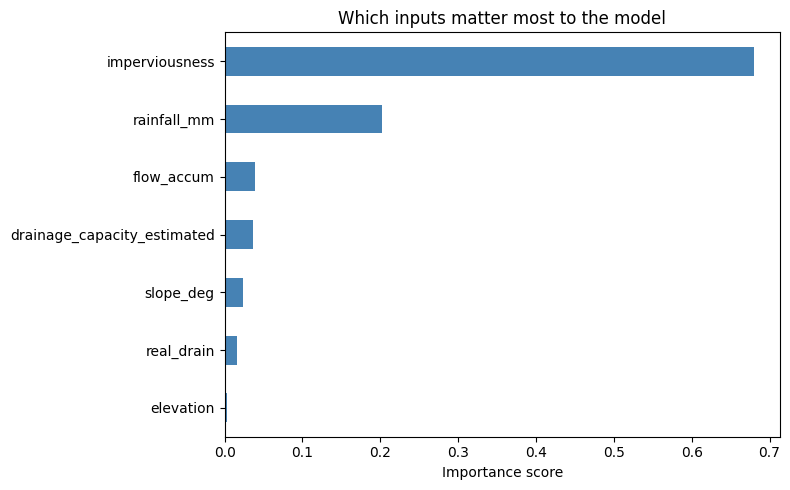

In [23]:
"""
Trains an XGBoost model to predict flood depth (cm) from terrain,
drainage, and rainfall features. Saves the trained model to disk.
"""
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import xgboost as xgb
import matplotlib.pyplot as plt
import pickle

# ============================================================
# STEP 1: Load the training data
# ============================================================
df = pd.read_csv("training_data.csv")

# Features = the inputs the model learns from
# Target = the thing we're trying to predict
feature_columns = [
    "elevation",
    "slope_deg",
    "flow_accum",
    "imperviousness",
    "real_drain",
    "drainage_capacity_estimated",
    "rainfall_mm",
]
target_column = "flood_depth_cm"

X = df[feature_columns]   # X = inputs (by ML convention, capital X means "the table of features")
y = df[target_column]     # y = the correct answer for each row (lowercase y = a single column)

# ============================================================
# STEP 2: Split into training data and testing data
# ============================================================
# We hold back 20% of the data that the model NEVER sees while learning,
# so we can honestly check afterward how well it predicts on new/unseen rows.
# random_state=42 just makes the split repeatable every time you run this.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Training on {len(X_train)} rows, testing on {len(X_test)} rows")

# ============================================================
# STEP 3: Train the XGBoost model
# ============================================================
# XGBoost (Extreme Gradient Boosting) builds many small decision trees one
# after another, where each new tree focuses on fixing the mistakes the
# previous trees made. n_estimators = how many trees to build.
model = xgb.XGBRegressor(
    n_estimators=300,       # number of trees to build
    max_depth=6,            # how many questions deep each tree can go
    learning_rate=0.05,     # how much each new tree corrects previous mistakes
    subsample=0.8,          # each tree trains on 80% of rows (adds robustness)
    colsample_bytree=0.8,   # each tree considers 80% of features (adds robustness)
    random_state=42,
    n_jobs=-1                # use all available CPU cores to train faster
)

model.fit(X_train, y_train)
print("Training complete.")

# ============================================================
# STEP 4: Evaluate on the held-back test data
# ============================================================
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\n--- Model Performance on Unseen Test Data ---")
print(f"MAE  (Mean Absolute Error):        {mae:.3f} cm")
print(f"RMSE (Root Mean Squared Error):    {rmse:.3f} cm")
print(f"R²   (R-squared, fit quality):     {r2:.3f}")

# ============================================================
# STEP 5: Which features actually mattered most?
# ============================================================
importance = pd.Series(model.feature_importances_, index=feature_columns)
importance = importance.sort_values(ascending=False)

print("\n--- Feature Importance ---")
print(importance)

plt.figure(figsize=(8, 5))
importance.plot(kind="barh", color="steelblue")
plt.title("Which inputs matter most to the model")
plt.xlabel("Importance score")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=150)
print("\nSaved feature_importance.png")

# ============================================================
# STEP 6: Save the trained model to disk
# ============================================================
with open("model.pkl", "wb") as f:
    pickle.dump(model, f)

print("Saved model.pkl")